# Phase 2: reproducing the paper
Yang et al. (2020) train **A2C, PPO and DDPG** every quarter on a growing window, pick the one with the best Sharpe ratio on the next 3 months (validation), and let it trade the following quarter. When the **turbulence index** is above a threshold, they sell everything.

We do the same on the point-in-time DJIA from **Oct 2000 to Dec 2025** (101 quarters), with **5 random seeds**. `train.py` trained the agents and `backtest.py` ran the trading. This notebook only reads the results.

**Differences from the paper:**

| | Paper | Here |
|---|---|---|
| Stocks | the 30 DJIA members on 1 Jan 2016, held fixed, 2009–2020 | the DJIA members of each day (no survivorship bias), 2000–2025 |
| Prices | adjusted close, no dividends | CRSP total returns (dividends and delisting returns) |
| Timing | trades at the close it just saw | trades at the next day's close |
| State | 181 raw numbers ($ cash, prices, share counts, indicators) | the same 181, scaled to about ±1 (cash share, daily returns, weights, indicators) |
| Trade size | up to 100 shares per stock per day | up to 1% of the portfolio per stock per day |
| Reward | change in $ value | daily return in % |
| Library | stable-baselines (TensorFlow) | stable-baselines3 (PyTorch), same algorithms and network size, training steps from the authors' code |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from backtest import STRATEGIES, pretty, sharpe, summary

bt = pd.read_parquet('results/backtest.parquet')
bt = bt[(bt.seed < 5) & bt.variant.isin(['baseline', 'fta'])]   # main runs (extra seeds and 'rolling': 6_investigation)
baselines = pd.read_parquet('results/baselines.parquet')
paper = bt[(bt.variant == 'baseline') & (bt.rule == 'sell')]   # the paper's setup: no FTA, sell everything when turbulent
print(paper.seed.nunique(), 'seeds,', paper.fold.nunique(), 'quarters')

5 seeds, 101 quarters


In [2]:
bt

,date,ret,turbulent,cash,held,turnover,put_paid,put_payoff,variant,seed,strategy,rule,fold,agent
0,2000-10-02,-0.000029,False,9.708118e-01,7,0.029188,0.0,0.0,baseline,0,ensemble,none,0,a2c
1,2000-10-03,0.000332,False,9.458332e-01,9,0.032832,0.0,0.0,baseline,0,ensemble,none,0,a2c
2,2000-10-04,0.000273,False,9.232312e-01,14,0.023347,0.0,0.0,baseline,0,ensemble,none,0,a2c
3,2000-10-05,0.000165,False,8.986679e-01,15,0.040397,0.0,0.0,baseline,0,ensemble,none,0,a2c
4,2000-10-06,-0.001494,False,8.843889e-01,12,0.039052,0.0,0.0,baseline,0,ensemble,none,0,a2c
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76195,2025-12-24,0.007043,False,0.000000e+00,9,0.003023,0.0,0.0,fta,4,ddpg,put,100,ddpg
76196,2025-12-26,0.005636,False,0.000000e+00,10,0.051461,0.0,0.0,fta,4,ddpg,put,100,ddpg
76197,2025-12-29,-0.005539,False,0.000000e+00,9,0.046093,0.0,0.0,fta,4,ddpg,put,100,ddpg
76198,2025-12-30,-0.002667,False,-2.611027e-18,8,0.034573,0.0,0.0,fta,4,ddpg,put,100,ddpg


## Same period as the paper (Jan 2016 – May 2020)
The paper's Table II first, then ours over the same dates (average of 5 seeds).

In [3]:
paper_table = pd.DataFrame({
    'Cumulative return': [.704, .830, .600, .548, .317, .386],
    'Annual return': [.130, .150, .114, .105, .065, .078],
    'Annual volatility': [.097, .136, .104, .123, .178, .201],
    'Sharpe (rf = 0)': [1.30, 1.10, 1.12, 0.87, 0.45, 0.47],
    'Max drawdown': [-.097, -.237, -.102, -.148, -.343, -.371],
}, index=['ensemble', 'ppo', 'a2c', 'ddpg', 'Min-variance', 'DJIA'])
pretty(paper_table)

,Cumulative return,Annual return,Annual volatility,Sharpe (rf = 0),Max drawdown
ensemble,70.4%,13.0%,9.7%,1.30,-9.7%
ppo,83.0%,15.0%,13.6%,1.10,-23.7%
a2c,60.0%,11.4%,10.4%,1.12,-10.2%
ddpg,54.8%,10.5%,12.3%,0.87,-14.8%
Min-variance,31.7%,6.5%,17.8%,0.45,-34.3%
DJIA,38.6%,7.8%,20.1%,0.47,-37.1%


In [4]:
mask = (
    paper['date'].between('2016-01-04', '2020-05-08')
    & (paper['strategy'] == 'ensemble')
    & (paper['variant'] == 'baseline')
    & (paper['rule'] == 'sell')
    & (paper['seed'] == 4)
)
r = paper.loc[mask].sort_values('date')['ret']
equity = (1 + r).cumprod()
equity

46093    0.986880
46094    0.987984
46095    0.973783
46096    0.952097
46097    0.941370
           ...   
58933    1.290924
58934    1.301413
58935    1.292556
58936    1.298993
58937    1.321957
Name: ret, Length: 1095, dtype: float64

In [5]:
ours_2016 = summary(paper, baselines, '2016-01-04', '2020-05-08')
pretty(ours_2016.loc[paper_table.index])

,Cumulative return,Annual return,Annual volatility,Sharpe (rf = 0),Sharpe (excess),Max drawdown,Sharpe std over seeds
ensemble,37.2%,7.4%,14.5%,0.56,0.47,-20.6%,0.23
ppo,30.7%,6.3%,13.1%,0.54,0.44,-20.5%,0.11
a2c,33.8%,6.9%,14.9%,0.52,0.43,-21.4%,0.14
ddpg,37.2%,7.5%,14.8%,0.56,0.47,-19.3%,0.17
Min-variance,55.3%,10.7%,16.6%,0.69,0.61,-30.3%,
DJIA,55.4%,10.7%,20.1%,0.61,0.54,-36.8%,


## Full period (Oct 2000 – Dec 2025)

In [6]:
full = summary(paper, baselines)
pretty(full)

,Cumulative return,Annual return,Annual volatility,Sharpe (rf = 0),Sharpe (excess),Max drawdown,Sharpe std over seeds
a2c,287.6%,5.5%,16.0%,0.41,0.30,-40.8%,0.06
ddpg,291.5%,5.5%,16.7%,0.41,0.30,-49.0%,0.03
ensemble,304.1%,5.6%,15.9%,0.43,0.31,-41.5%,0.05
ppo,366.5%,6.3%,13.3%,0.52,0.39,-32.1%,0.06
DJIA,716.7%,8.7%,18.3%,0.55,0.45,-51.8%,
Min-variance,508.3%,7.4%,14.4%,0.57,0.44,-31.5%,
1/N,748.9%,8.9%,19.5%,0.53,0.44,-60.0%,
Random agent,254.9%,5.2%,18.3%,0.37,0.27,-57.2%,


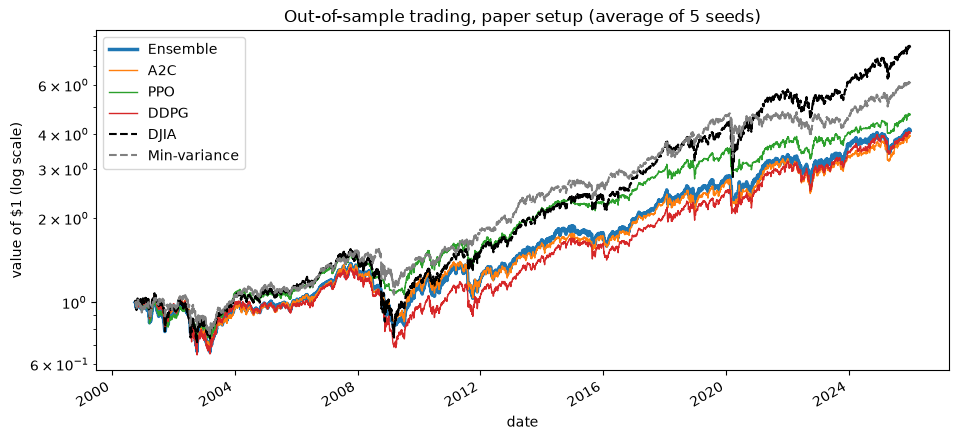

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for s in STRATEGIES:
    r = paper[paper.strategy == s].groupby('date').ret.mean()      # average of the 5 seeds
    (1 + r).cumprod().plot(ax=ax, label=s.upper() if s != 'ensemble' else 'Ensemble', lw=2.5 if s == 'ensemble' else 1)
for b in ['DJIA', 'Min-variance']:
    (1 + baselines[b]).cumprod().plot(ax=ax, label=b, ls='--', color='black' if b == 'DJIA' else 'gray')
ax.set_yscale('log')
ax.set_ylabel('value of $1 (log scale)')
ax.set_title('Out-of-sample trading, paper setup (average of 5 seeds)')
ax.legend();

## Which agent did the ensemble pick?

In [8]:
picks = paper[paper.strategy == 'ensemble'].groupby(['seed', 'fold']).agent.first()
picks.value_counts(normalize=True).round(2)

agent
ddpg    0.44
a2c     0.31
ppo     0.25
Name: proportion, dtype: float64

rule
sell    31750
Name: count, dtype: int64

## Conclusion
- **The paper's headline result doesn't replicate.** Over the paper's own period (Jan 2016 – May 2020) the ensemble's Sharpe ratio is **0.56**, against **1.30** in the paper and **0.61** for the DJIA. Over the full 25 years it's **0.43**, against 0.55 for the DJIA and 0.57 for min-variance.
- **What does replicate:** the agents take less risk than the index, as in the paper. Over 2000–2025 the ensemble's volatility is 16% against 18% for the DJIA, and its max drawdown −42% against −52%. Most of that comes from the turbulence rule selling before crashes; without it the drawdown is −57% (notebook 5).
- **The ensemble doesn't beat its best member.** PPO on its own (Sharpe 0.52) does better than the ensemble (0.43). Choosing an agent from 3 months of validation is noisy: the ensemble picks DDPG most often (44% of quarters), although DDPG and A2C are the weakest agents on their own (Sharpe 0.41 each).
- **Likely reasons for the gap with the paper:**
  - We use the actual DJIA members of each day, so there is no survivorship bias. Over the full 25 years, the test is also longer and harder (2000–2002, 2008).
  - We trade with a one-day lag.
  - Our DJIA includes dividends.
  - We average 5 seeds; the paper reports a single run.